# Reproducible Data Workflow: Titanic Survival Analysis

**Author:** Sandip Dey  
**Dataset:** Titanic - Machine Learning from Disaster  
**Source:** https://www.kaggle.com/c/titanic/data (public mirror used for this notebook)

This notebook implements a complete, reproducible data workflow: loading, cleaning, exploratory analysis, visualization, and interpretation of the Titanic passenger dataset. The goal is to understand factors associated with survival while demonstrating modular, documented code suitable for future machine learning work.

## 1. Import Libraries and Load Dataset

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for consistent, publication-quality plots
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load the dataset
df = pd.read_csv("titanic.csv")
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Data Cleaning Functions

Two modular cleaning functions with docstrings are defined below. They are applied sequentially to produce a cleaned DataFrame.

In [8]:
def handle_missing_values(df):
    """
    Handle missing values in the Titanic dataset.
    
    - Age: fill with median (robust to outliers)
    - Embarked: fill with mode (most common port)
    - Cabin: drop column (too many missing values to be useful)
    
    Parameters
    ----------
    df : pd.DataFrame
        Raw Titanic DataFrame
    
    Returns
    -------
    pd.DataFrame
        DataFrame with missing values addressed
    """
    df = df.copy()
    df["Age"] = df["Age"].fillna(df["Age"].median())
    df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
    df = df.drop(columns=["Cabin"])
    return df


def create_derived_features(df):
    """
    Create useful derived features for analysis.
    
    - FamilySize: SibSp + Parch + 1
    - IsAlone: 1 if FamilySize == 1, else 0
    - Title: extracted from Name (Mr, Mrs, Miss, etc.)
    
    Parameters
    ----------
    df : pd.DataFrame
        DataFrame after missing-value handling
    
    Returns
    -------
    pd.DataFrame
        DataFrame with new features added
    """
    df = df.copy()
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)
    df["Title"] = df["Name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
    # Group rare titles
    rare_titles = ["Dr", "Rev", "Col", "Major", "Capt", "Countess", "Lady", "Sir", "Jonkheer", "Don", "Dona"]
    df["Title"] = df["Title"].replace(rare_titles, "Rare")
    df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    return df


# Apply cleaning functions
df_clean = handle_missing_values(df)
df_clean = create_derived_features(df_clean)

print("Missing values after cleaning:")
print(df_clean.isnull().sum())
print("\nNew features sample:")
df_clean[["FamilySize", "IsAlone", "Title"]].head(10)

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
FamilySize     0
IsAlone        0
Title          0
dtype: int64

New features sample:


,FamilySize,IsAlone,Title
0,2,0,Mr
1,2,0,Mrs
2,1,1,Miss
3,2,0,Mrs
4,1,1,Mr
5,1,1,Mr
6,1,1,Mr
7,5,0,Master
8,3,0,Mrs
9,2,0,Mrs


## 3. Exploratory Analysis Function

In [9]:
def exploratory_analysis(df):
    """
    Perform key exploratory data analysis on the cleaned Titanic dataset.
    
    Returns summary statistics, survival rates by key groups, and correlation matrix.
    
    Parameters
    ----------
    df : pd.DataFrame
        Cleaned Titanic DataFrame
    
    Returns
    -------
    dict
        Dictionary containing analysis results
    """
    results = {}
    results["summary_stats"] = df.describe(include="all")
    results["survival_by_sex"] = df.groupby("Sex")["Survived"].mean()
    results["survival_by_class"] = df.groupby("Pclass")["Survived"].mean()
    results["survival_by_alone"] = df.groupby("IsAlone")["Survived"].mean()
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    results["correlation"] = df[numeric_cols].corr()
    return results


eda_results = exploratory_analysis(df_clean)
print("Survival rate by Sex:")
print(eda_results["survival_by_sex"])
print("\nSurvival rate by Passenger Class:")
print(eda_results["survival_by_class"])
print("\nSurvival rate by Alone status:")
print(eda_results["survival_by_alone"])

Survival rate by Sex:
Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

Survival rate by Passenger Class:
Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

Survival rate by Alone status:
IsAlone
0    0.505650
1    0.303538
Name: Survived, dtype: float64


## 4. Visualizations

Three visualizations with titles and labeled axes.

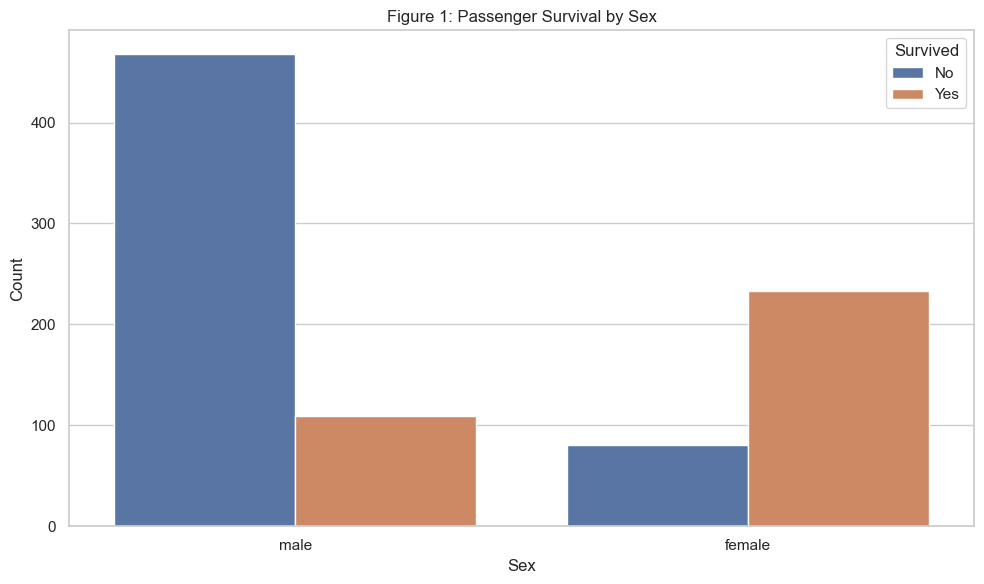

In [10]:
# Figure 1: Survival by Sex
plt.figure()
sns.countplot(data=df_clean, x="Sex", hue="Survived")
plt.title("Figure 1: Passenger Survival by Sex")
plt.xlabel("Sex")
plt.ylabel("Count")
plt.legend(title="Survived", labels=["No", "Yes"])
plt.tight_layout()
plt.show()

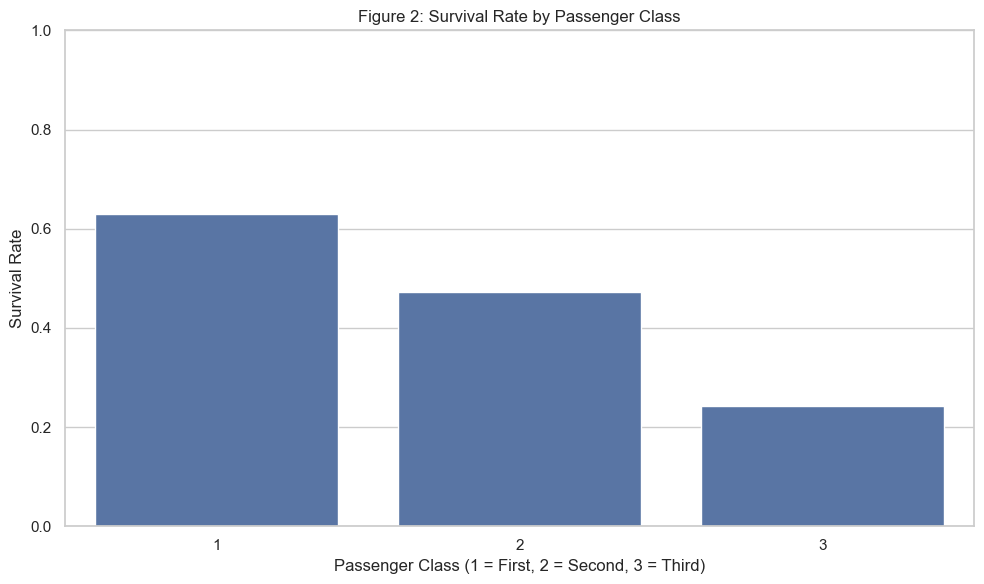

In [11]:
# Figure 2: Survival by Passenger Class
plt.figure()
sns.barplot(data=df_clean, x="Pclass", y="Survived", errorbar=None)
plt.title("Figure 2: Survival Rate by Passenger Class")
plt.xlabel("Passenger Class (1 = First, 2 = Second, 3 = Third)")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

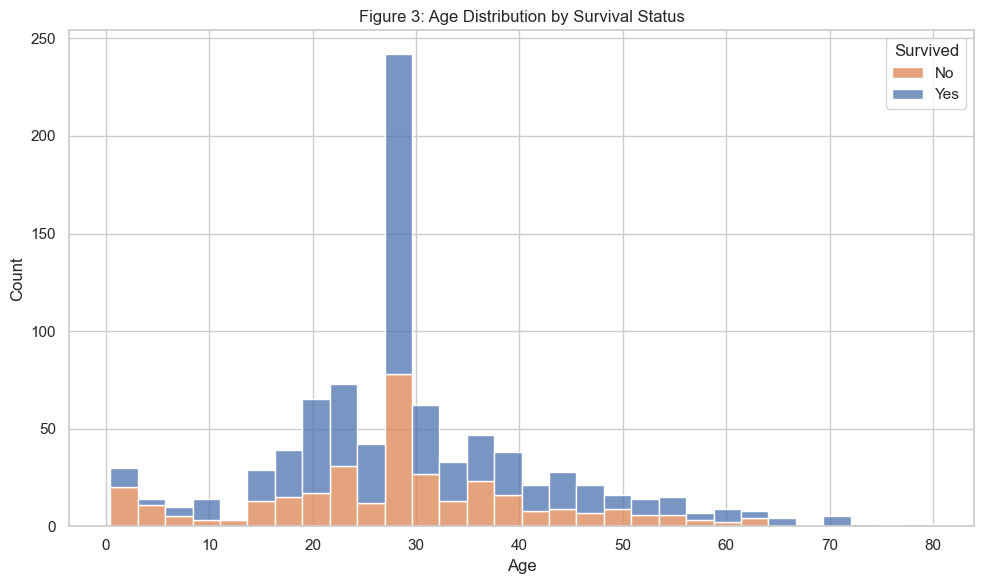

In [12]:
# Figure 3: Age distribution by Survival
plt.figure()
sns.histplot(data=df_clean, x="Age", hue="Survived", multiple="stack", bins=30)
plt.title("Figure 3: Age Distribution by Survival Status")
plt.xlabel("Age")
plt.ylabel("Count")
plt.legend(title="Survived", labels=["No", "Yes"])
plt.tight_layout()
plt.show()

## 5. Summary and Interpretation

The Titanic dataset (891 passengers, 12 original columns) reveals clear patterns in survival. Women had substantially higher survival rates than men (approximately 74% vs 19%). First-class passengers survived at higher rates than second- or third-class passengers. Traveling alone was associated with lower survival. Age shows a bimodal pattern, with children and some older adults having different outcomes, though missing ages were imputed with the median.

**Interesting patterns:** Sex and class are the strongest observable predictors. Family size appears to have a non-linear effect (small families fared better than large ones or solitary travelers).

**Limitations and assumptions:** Age imputation with the median assumes missingness is unrelated to survival after conditioning on other variables (MAR). Cabin was dropped due to high missingness. The dataset is a historical snapshot and does not include all passengers. Results are descriptive, not causal.

**Surprising / unclear:** The strength of the sex effect is striking even after accounting for class. Some titles (e.g., Master) indicate children and show higher survival, which aligns with the “women and children first” protocol but is not fully captured by Age alone.